In [9]:
# 필요한 라이브러리 불러오기
import numpy as np              # 넘파이: 숫자 계산
import pandas as pd             # 판다스: 데이터 정리
import yfinance as yf           # 와이파이낸스: 주식 데이터 수집
import matplotlib.pyplot as plt # 맷플롯립: 그래프 출력
from sklearn.preprocessing import MinMaxScaler  # 민맥스 스케일러: 숫자 범위 정규화
from tensorflow.keras.models import Sequential   # 시퀀셜: 모델 층을 순서대로 쌓기
from tensorflow.keras.layers import LSTM, Dense  # LSTM: 순서 데이터 학습 / Dense: 최종 계산

# 🍔 햄버거 재료와 조리 도구 준비

ModuleNotFoundError: No module named 'sklearn'

In [3]:
# 1. 데이터 수집
ticker = "AAPL"  # 애플 주식 코드
data = yf.download(ticker, start="2015-01-01", end="2024-01-01")  # 2015~2023년 주가 수집
data = data[['Close']]  # 종가만 선택

# 🍔 여러 재료 중 햄버거 가격에 필요한 재료만 골라오기

[*********************100%***********************]  1 of 1 completed


In [4]:
# 데이터 앞부분 5개 확인
data.head()  # 처음 5개 행 출력

# 🍔 준비한 재료 목록에서 맨 위 5개 확인

Price,Close
Ticker,AAPL
Date,
2015-01-02,24.171747
2015-01-05,23.490805
2015-01-06,23.493017
2015-01-07,23.822433
2015-01-08,24.737751


In [5]:
# 2. 데이터 전처리
scaler = MinMaxScaler(feature_range=(0, 1))  # 데이터를 0~1 사이의 값으로 바꾸는 도구
scaled_data = scaler.fit_transform(data)  # 데이터의 최솟값은 0, 최댓값은 1로 변환

# 🍔 재료마다 크기가 다르니, 같은 기준으로 맞춰서 비교하기

In [6]:
# 과거 60일 데이터를 보고 다음 날 주가를 예측하는 데이터 만들기
def create_dataset(dataset, look_back=60):  # look_back: 과거 데이터를 몇 개 사용할지 설정
    X, y = [], []  # X: 과거 60일 데이터, y: 다음 날 정답 데이터

    for i in range(len(dataset) - look_back):  # 데이터 끝까지 60일씩 이동
        X.append(dataset[i:i + look_back, 0])  # 과거 60일 종가를 X에 저장
        y.append(dataset[i + look_back, 0])  # 그다음 날 종가를 정답 y에 저장

    return np.array(X), np.array(y)  # 리스트를 넘파이 배열로 변환해서 반환

# 🍔 햄버거를 만들 때 과거 60번의 주문을 보고 다음 주문을 예상하기

In [7]:
# 과거 60일 데이터를 기준으로 학습 데이터 만들기
look_back = 60  # 과거 60일의 주가를 보고 다음 날 주가 예측

X, y = create_dataset(scaled_data, look_back)  # 입력 데이터 X와 정답 데이터 y 생성

# LSTM이 이해할 수 있는 3차원 형태로 변환
X = np.reshape(X, (X.shape[0], X.shape[1], 1))
# X.shape[0]: 전체 샘플 수
# X.shape[1]: 과거 60일(시퀀스 길이)
# 1: 종가라는 피처(특성) 1개

# 🍔 과거 60일 주문 기록을 한 묶음으로 만들어 다음 주문 예측하기

In [8]:
# 3. 모델 구성
model = Sequential([  # 신경망 층을 순서대로 쌓아 모델 구성

    LSTM(50, return_sequences=True, input_shape=(X.shape[1], 1)),
    # 첫 번째 LSTM 층: 과거 60일의 주가 패턴 학습
    # 50: 학습에 사용할 뉴런(유닛) 50개
    # return_sequences=True: 다음 LSTM 층에 전체 시퀀스 전달
    # input_shape: (시퀀스 길이, 피처 수)

    LSTM(50),  # 두 번째 LSTM 층: 앞에서 전달된 패턴을 학습해 요약

    Dense(1)  # 최종 출력층: 다음 날 주가 예측값 1개 출력
])

# 🍔 첫 번째 요리사가 60일 주문 흐름을 살피고,
# 두 번째 요리사가 핵심을 정리한 뒤 최종 가격을 내놓기

c:\Users\human-01\OneDrive\Desktop\Python_AI_Lab\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
# 모델 학습 방식 설정
model.compile(
    optimizer='adam',  # 아담: 빠르고 효율적으로 오차를 줄이는 센스 있는 주방장
    loss='mean_squared_error'  # 평균제곱오차: 예측값과 실제값의 차이를 제곱해 평균 계산
)

# 🍔 주방장이 손님 평가와 실제 맛의 차이를 줄이도록 조리법을 조정하기

In [10]:
# 4. 모델 학습용 데이터와 시험용 데이터 분리
train_size = int(len(X) * 0.8)  # 전체 데이터의 80%를 학습용으로 설정

X_train, X_test = X[:train_size], X[train_size:]  # 문제지를 80%와 20%로 분리
y_train, y_test = y[:train_size], y[train_size:]  # 정답지도 같은 기준으로 분리

# 🍔 80%는 연습 문제, 20%는 실전 시험 문제!

In [11]:
# 모델 학습 시작
model.fit(
    X_train, y_train,  # 학습용 문제지와 정답지
    epochs=20,         # 전체 학습 데이터를 20번 반복 학습
    batch_size=32,     # 한 번에 32개씩 묶어서 학습
    validation_data=(X_test, y_test),  # 시험용 데이터로 학습 중 성능 확인
    shuffle=False      # 시간 순서가 중요하므로 데이터 섞지 않기
)

# 🍔 연습 문제를 20회 반복해서 풀고,
# 32개씩 묶어 학습하면서 시험 문제로 중간 점검하기

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - loss: 0.0012 - val_loss: 0.0038
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0047 - val_loss: 0.0021
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0037 - val_loss: 0.0046
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0037 - val_loss: 0.0084
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.0025 - val_loss: 0.0028
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 7.2500e-04 - val_loss: 9.8392e-04
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 6.7260e-04 - val_loss: 0.0012
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 3.0713e-04 - val_loss: 8.3978e-04
Epoch 9/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 3.3987e-04 - val_loss: 8.1093e-04
Epoch 10/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 3.1651e-04 - val_loss: 7.9161e-04
Epoch 11/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 3.1392e-04 - val_loss: 7.6526e-04
Epoch 12/20
56/56 ━

In [12]:
# 5. 예측 및 시각화
predictions = model.predict(X_test)  # 시험용 문제를 모델에 넣어 주가 예측

predictions = scaler.inverse_transform(predictions.reshape(-1, 1))
# reshape(-1, 1): 예측값을 (샘플 수, 1) 형태의 2차원 배열로 변환
# inverse_transform: 0~1로 정규화했던 예측값을 실제 주가 범위로 되돌리기

# 🍔 축소해 놓았던 햄버거 가격을 원래 가격 단위로 복원하기

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step


In [13]:
# 실제 값 복원
actual_prices = scaler.inverse_transform(y_test.reshape(-1, 1))
# reshape(-1, 1): 배열을 2차원 형태로 변경
# -1: 전체 데이터 개수에 맞춰 행의 개수를 자동 계산
# 1: 열을 1개로 지정 (실제 주가라는 데이터 1개)
# inverse_transform: 0~1로 정규화했던 실제 주가를 원래 가격으로 복원

# 🍔 햄버거 가격표를 한 줄씩 세우고, 원래 가격으로 되돌리기

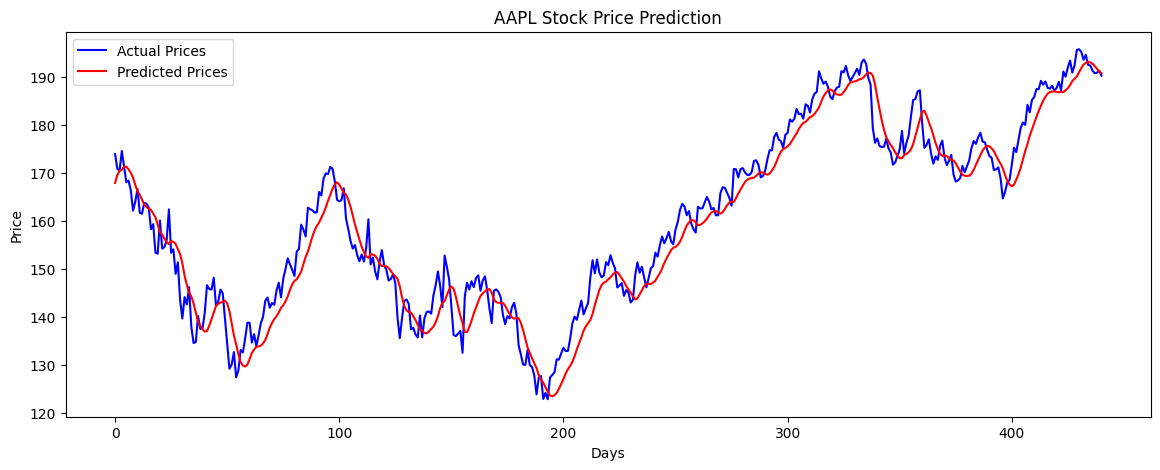

In [14]:
# 실제 주가와 예측 주가 비교 그래프
plt.figure(figsize=(14, 5))  # 그래프 크기 설정 (가로 14, 세로 5)

plt.plot(actual_prices, label="Actual Prices", color='blue')
# 실제 주가를 파란색 선으로 표시

plt.plot(predictions, label="Predicted Prices", color='red')
# 모델이 예측한 주가를 빨간색 선으로 표시

plt.title(f'{ticker} Stock Price Prediction')  # 그래프 제목 (애플 주가 예측)
plt.xlabel('Days')       # X축: 날짜의 흐름
plt.ylabel('Price')      # Y축: 주가
plt.legend()             # 파란색과 빨간색 선의 범례 표시
plt.show()               # 완성된 그래프 화면에 출력

# 🍔 실제 햄버거 가격표와 요리사가 예상한 가격표를
# 파란색과 빨간색 선으로 나란히 비교하기